In [68]:
from config import *

import Operators2D as Op

class twoD_Minimal_Model:

    def __init__(self, n, nsm, nsc, m, ax, ay, omega=1, alphat=0, delta=0, meff_sc=1, meff_sm = 1 , mu_sc = 0, mu_sm=0, dis_mean=0, dis_var=1, px=False, py=False,  epsilon=0):

        """
        Initializes a new instance of the oneD_Minimal_Model class.
        
        Args:
            n (int): The number of horizontal lattice points of the system.
            nsm (int): The number of horizontal lattice points of the semiconductor weak link.
            nsc (int): The number of horizontal lattice points of the superconductor on both sides.
            m (int): The number of vertical lattive points
            ax (float): The horizontal (x) lattice spacing.
            ay (float): The vertical (y) lattice spacing.
            meff (float): Effective mass 
            alphat (float): spin orbit coupling constant
            mu_s (float): chemical potential of the superconducting region of SNS
            mu_sm (float): chemical potential of the semiconductingconducting region of SNS
            px (bool, optional): Flag indicating periodicity in x direction. Defaults to False.
            epsilon (float): Kx^4 prefactor to remove higher k states from dipping

        Notes:
            - The ordering of lattice points for kx, kxsq, kxcu(imported for operator class file) is from left to right, bottom to top, similar to x and y axis in 2D g

        """

        self.n = n
        self.nsm = nsm
        self.nsc = nsc
        self.m = m
        self.ax = ax
        self.ay = ay
        self.omega = omega
        self.meff_sc = meff_sc
        self.meff_sm = meff_sm
        self.alphat = alphat
        self.delta = delta
        self.mu_sc = mu_sc
        self.mu_sm  = mu_sm
        self.dis_mean = dis_mean
        self.dis_var = dis_var
        self.px = px
        self.py = py
        self.epsilon = epsilon
        self.twodOP = Op.Operators_2d(self.n, self.m, self.ax, self.ay, self.px, self.py)

    def ysq_matrix(self):

        row = np.empty(0)
        col = np.empty(0)
        data = np.empty(0)

        shift = (((self.m//2))*self.ay)

        #print('SHIFT YSQ: ', shift )

        for j in range(self.m):

            for i in range(self.n):
            
                row = np.append(row, j*self.n + i)
                col = np.append(col, j*self.n + i)
                data = np.append(data, ((j)*self.ay-shift)**2)

        M = csr_matrix((data,(row,col)),shape=(self.m*self.n, self.m*self.n))

        return M

    def SHO_wvfn(self, ne):
        # define constant of SHo wavefunctions 

        kappa = self.omega/hbm*self.meff_sm
        normalization_const = 1/math.sqrt(2**ne * math.factorial(ne))*(kappa/2/math.pi)**(0.25)

        # Create the Hermite polynomial 
        coefficients = np.zeros(ne+1)
        coefficients[ne] = 1  # Setting the leading coefficient as per the physicist's definition
        
        H_n = Hermite(coefficients)

        shift = (((self.m//2))*self.ay) ### same shift from as the ysq_matrix 

        #print('SHIFT Y_array: ', shift )

        indices = np.arange(self.m * self.n)

        y_array = (indices // self.n) * self.ay  - shift

        y_array_n = math.sqrt(kappa/2)*y_array

        Herm_array = H_n(y_array_n)

        return normalization_const*np.exp(-kappa/4*y_array**2)*Herm_array, y_array        

    def SHO_pot(self):

        return 1/4/hbm*self.meff_sm*self.omega**2*self.ysq_matrix() 

    def Basis_change_operator(self, no_of_subbands):

        return None 
        

In [75]:
N = 3
NSM = 3 
NSC = 1 
M = 13 
AX = 1
AY = 1 

A = twoD_Minimal_Model(N,NSM,NSC,M,AX,AY)

#print(A.ysq_matrix())

ysq = A.ysq_matrix()

b,c = A.SHO_wvfn(1)
print(c)

print(b)

d = A.SHO_pot()

[-6 -6 -6 -5 -5 -5 -4 -4 -4 -3 -3 -3 -2 -2 -2 -1 -1 -1  0  0  0  1  1  1
  2  2  2  3  3  3  4  4  4  5  5  5  6  6  6]
[-0.19504447 -0.19504447 -0.19504447 -0.17469179 -0.17469179 -0.17469179
 -0.14824771 -0.14824771 -0.14824771 -0.11640731 -0.11640731 -0.11640731
 -0.08019095 -0.08019095 -0.08019095 -0.04089189 -0.04089189 -0.04089189
  0.          0.          0.          0.04089189  0.04089189  0.04089189
  0.08019095  0.08019095  0.08019095  0.11640731  0.11640731  0.11640731
  0.14824771  0.14824771  0.14824771  0.17469179  0.17469179  0.17469179
  0.19504447  0.19504447  0.19504447]


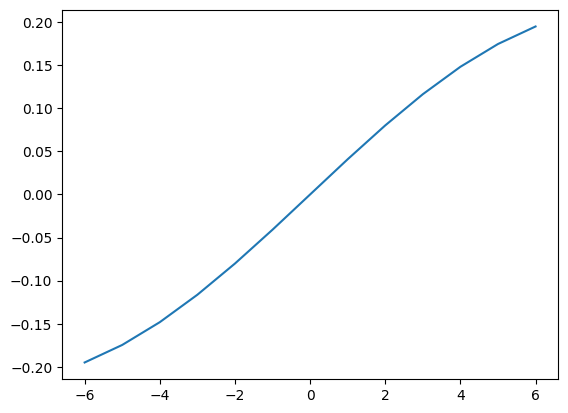

In [77]:
plt.plot(c, b)
#plt.plot(c, d.diagonal())